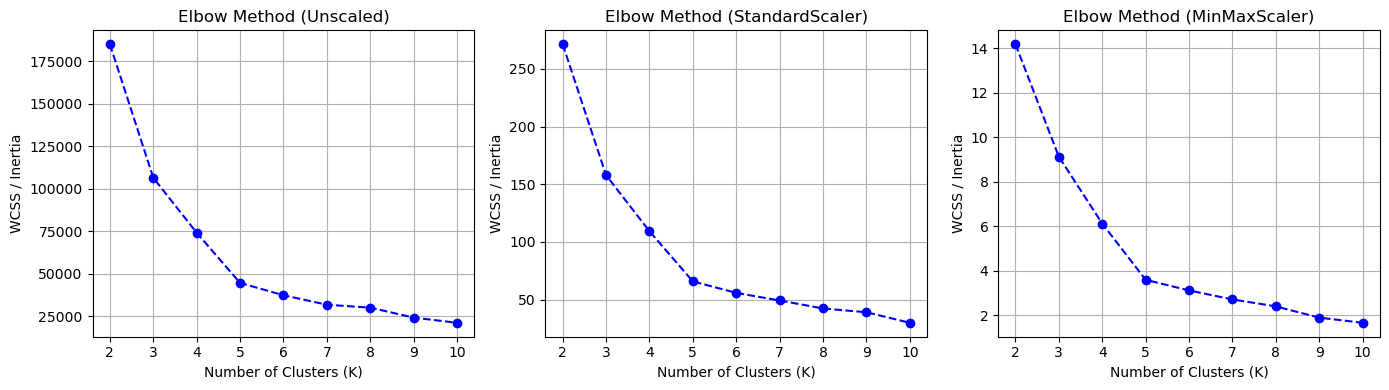

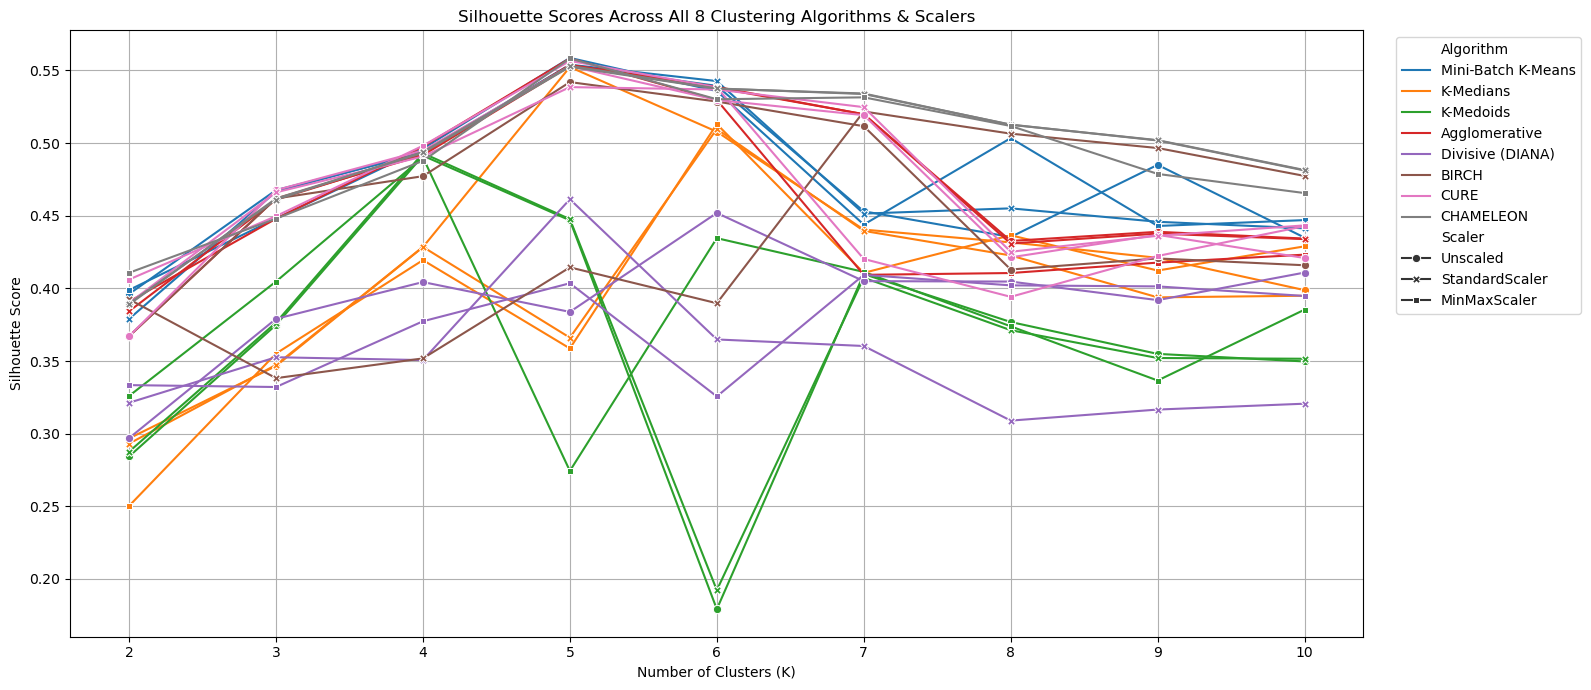

--- Maximum Silhouette Scores Matrix ---
Scaler              MinMaxScaler  StandardScaler  Unscaled
Algorithm                                                 
Agglomerative             0.5583          0.5538    0.5530
BIRCH                        NaN          0.5217    0.5420
CHAMELEON                 0.5583          0.5531    0.5525
CURE                      0.5566          0.5385    0.5530
Divisive (DIANA)          0.4093          0.4613    0.4519
K-Medians                 0.5131          0.5097    0.5523
K-Medoids                 0.4901          0.4930    0.4913
Mini-Batch K-Means        0.5586          0.5539    0.5532

>>> WINNING MODEL: Mini-Batch K-Means (MinMaxScaler, K=5)
>>> Silhouette Score: 0.5586


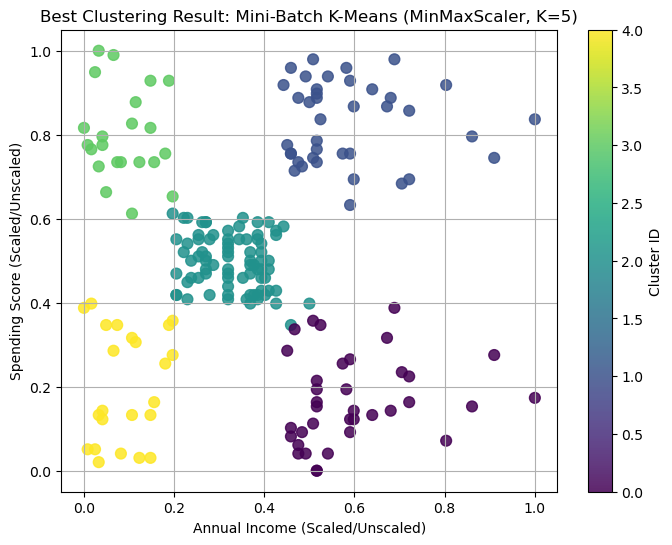

Model saved to: models/best_clustering_mini-batch_k-means.pkl


In [7]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score, pairwise_distances
from sklearn.cluster import (
    MiniBatchKMeans, 
    AgglomerativeClustering, 
    Birch,
    KMeans
)
from sklearn_extra.cluster import KMedoids

# =====================================================================
# CUSTOM ALGORITHM IMPLEMENTATIONS (For Non-Native Scikit-Learn Models)
# =====================================================================

class KMedians:
    """Centroid-Based: K-Medians Clustering using L1-distance (Manhattan)."""
    def __init__(self, n_clusters=5, max_iter=300, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state

    def fit_predict(self, X):
        np.random.seed(self.random_state)
        # Random initial centroids
        indices = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        self.cluster_centers_ = X[indices]
        
        for _ in range(self.max_iter):
            # Calculate Manhattan distances
            distances = pairwise_distances(X, self.cluster_centers_, metric='manhattan')
            labels = np.argmin(distances, axis=1)
            
            # Update medians
            new_centers = np.array([
                np.median(X[labels == k], axis=0) if np.sum(labels == k) > 0 else self.cluster_centers_[k]
                for k in range(self.n_clusters)
            ])
            
            if np.allclose(self.cluster_centers_, new_centers):
                break
            self.cluster_centers_ = new_centers
            
        return labels

class DivisiveDIANA:
    """Hierarchical: Divisive Analysis (DIANA) Top-Down Clustering."""
    def __init__(self, n_clusters=5):
        self.n_clusters = n_clusters

    def fit_predict(self, X):
        clusters = [list(range(len(X)))]
        
        while len(clusters) < self.n_clusters:
            # Pick cluster with maximum variance to split using 2-means
            largest_cluster_idx = np.argmax([len(c) for c in clusters])
            cluster_to_split = clusters.pop(largest_cluster_idx)
            
            if len(cluster_to_split) <= 1:
                clusters.append(cluster_to_split)
                break
                
            sub_X = X[cluster_to_split]
            km = KMeans(n_clusters=2, random_state=42, n_init=5).fit(sub_X)
            
            c0 = [cluster_to_split[i] for i in range(len(cluster_to_split)) if km.labels_[i] == 0]
            c1 = [cluster_to_split[i] for i in range(len(cluster_to_split)) if km.labels_[i] == 1]
            
            clusters.extend([c0, c1])
            
        labels = np.zeros(len(X), dtype=int)
        for cluster_id, idxs in enumerate(clusters):
            labels[idxs] = cluster_id
        return labels

class CUREClustering:
    """Hierarchical: Clustering Using Representatives (CURE)."""
    def __init__(self, n_clusters=5, n_rep=3, shrink_factor=0.3):
        self.n_clusters = n_clusters
        self.n_rep = n_rep
        self.shrink_factor = shrink_factor

    def fit_predict(self, X):
        # Step 1: Initialize Agglomerative clustering to build initial clusters
        base_agg = AgglomerativeClustering(n_clusters=self.n_clusters)
        labels = base_agg.fit_predict(X)
        
        # Step 2: Compute representative points for each cluster and shrink toward centroid
        rep_points = {}
        for c in range(self.n_clusters):
            pts = X[labels == c]
            if len(pts) == 0:
                continue
            centroid = np.mean(pts, axis=0)
            
            # Select diverse points
            if len(pts) <= self.n_rep:
                reps = pts
            else:
                reps = pts[np.random.choice(len(pts), self.n_rep, replace=False)]
                
            # Shrink toward centroid
            shrunken_reps = reps + self.shrink_factor * (centroid - reps)
            rep_points[c] = shrunken_reps

        # Reassign all data points to nearest shrunken representative set
        final_labels = np.zeros(len(X), dtype=int)
        for i, pt in enumerate(X):
            min_dist = float('inf')
            best_cluster = 0
            for c, reps in rep_points.items():
                dists = np.linalg.norm(reps - pt, axis=1)
                if np.min(dists) < min_dist:
                    min_dist = np.min(dists)
                    best_cluster = c
            final_labels[i] = best_cluster
            
        return final_labels

class CHAMELEONClustering:
    """Hierarchical: Two-phase Graph-based Clustering (CHAMELEON approximation)."""
    def __init__(self, n_clusters=5):
        self.n_clusters = n_clusters

    def fit_predict(self, X):
        # Phase 1: Dynamic fine-grained over-clustering
        pre_clusters = self.n_clusters * 3
        agg_phase1 = AgglomerativeClustering(n_clusters=min(pre_clusters, len(X)))
        initial_labels = agg_phase1.fit_predict(X)
        
        # Phase 2: Compute cluster centroids and merge based on spatial closeness
        centroids = np.array([X[initial_labels == i].mean(axis=0) for i in range(pre_clusters)])
        agg_phase2 = AgglomerativeClustering(n_clusters=self.n_clusters)
        meta_labels = agg_phase2.fit_predict(centroids)
        
        # Map original points to final merged clusters
        return meta_labels[initial_labels]


# =====================================================================
# MAIN PIPELINE
# =====================================================================

df = pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\Mall_Customers.csv") 


X_raw = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# 2. Scaler Mapping
scalers = {
    'Unscaled': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler()
}

scaled_data = {
    name: X_raw if scaler is None else scaler.fit_transform(X_raw)
    for name, scaler in scalers.items()
}

# 3. Comprehensive Model Mapping (All 8 Algorithms)
def get_algorithms(k):
    return {
        'Mini-Batch K-Means': MiniBatchKMeans(n_clusters=k, random_state=42, n_init=10),
        'K-Medians': KMedians(n_clusters=k, random_state=42),
        'K-Medoids': KMedoids(n_clusters=k, random_state=42),
        'Agglomerative': AgglomerativeClustering(n_clusters=k),
        'Divisive (DIANA)': DivisiveDIANA(n_clusters=k),
        'BIRCH': Birch(n_clusters=k),
        'CURE': CUREClustering(n_clusters=k),
        'CHAMELEON': CHAMELEONClustering(n_clusters=k)
    }

# 4. Elbow Method (WCSS / Inertia across Scalers using Mini-Batch K-Means)
K_range = range(2, 11)
plt.figure(figsize=(14, 4))

for i, (scaler_name, X_curr) in enumerate(scaled_data.items(), 1):
    wcss = []
    for k in K_range:
        mbkm = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=10)
        mbkm.fit(X_curr)
        wcss.append(mbkm.inertia_)
    
    plt.subplot(1, 3, i)
    plt.plot(K_range, wcss, marker='o', color='b', linestyle='--')
    plt.title(f'Elbow Method ({scaler_name})')
    plt.xlabel('Number of Clusters (K)')
    plt.ylabel('WCSS / Inertia')
    plt.grid(True)

plt.tight_layout()
plt.show()

# 5. Evaluate Silhouette Scores Across All Configurations
results = []
best_score = -1
best_model_info = None

for scaler_name, X_curr in scaled_data.items():
    for algo_name in get_algorithms(5).keys():
        for k in K_range:
            model = get_algorithms(k)[algo_name]
            labels = model.fit_predict(X_curr)
            
            if len(np.unique(labels)) > 1:
                score = silhouette_score(X_curr, labels)
                results.append({
                    'Scaler': scaler_name,
                    'Algorithm': algo_name,
                    'K': k,
                    'Silhouette Score': score,
                    'Model': model,
                    'Data': X_curr
                })
                
                if score > best_score:
                    best_score = score
                    best_model_info = {
                        'Scaler': scaler_name,
                        'Algorithm': algo_name,
                        'K': k,
                        'Score': score,
                        'Model': model,
                        'Data': X_curr,
                        'Labels': labels
                    }

results_df = pd.DataFrame(results)

# 6. Plot Silhouette Scores per Algorithm across Scalers
plt.figure(figsize=(16, 7))
sns.lineplot(
    data=results_df, 
    x='K', 
    y='Silhouette Score', 
    hue='Algorithm', 
    style='Scaler', 
    markers=True, 
    dashes=False
)
plt.title('Silhouette Scores Across All 8 Clustering Algorithms & Scalers')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Print Max Silhouette Scores Matrix
best_per_algo = results_df.loc[results_df.groupby(['Algorithm', 'Scaler'])['Silhouette Score'].idxmax()]
summary_table = best_per_algo.pivot(index='Algorithm', columns='Scaler', values='Silhouette Score')
print("--- Maximum Silhouette Scores Matrix ---")
print(summary_table.round(4))

# 8. Plot Best Overall Model & Save to Disk
print(f"\n>>> WINNING MODEL: {best_model_info['Algorithm']} ({best_model_info['Scaler']}, K={best_model_info['K']})")
print(f">>> Silhouette Score: {best_model_info['Score']:.4f}")

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    best_model_info['Data'][:, 0], 
    best_model_info['Data'][:, 1], 
    c=best_model_info['Labels'], 
    cmap='viridis', 
    s=60, 
    alpha=0.85
)
plt.title(f"Best Clustering Result: {best_model_info['Algorithm']} ({best_model_info['Scaler']}, K={best_model_info['K']})")
plt.xlabel('Annual Income (Scaled/Unscaled)')
plt.ylabel('Spending Score (Scaled/Unscaled)')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True)
plt.show()

os.makedirs("models", exist_ok=True)
model_path = f"models/best_clustering_{best_model_info['Algorithm'].lower().replace(' ', '_').replace('(', '').replace(')', '')}.pkl"
joblib.dump(best_model_info['Model'], model_path)
print(f"Model saved to: {model_path}")